**От деревьев к случайному лес**

## 1. Решающее дерево


Подгружаем необходимые библиотеки

In [81]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from tqdm.auto import trange

warnings.filterwarnings("ignore")

Подгрузка данных из  sklearn.datasets, и разделение данных на факторный и результативный признаки

In [82]:
california = fetch_california_housing()
california_X = pd.DataFrame(data=california.data, columns=california.feature_names)
california_Y = california.target
print(f"X shape: {california_X.shape}, Y shape: {california_Y.shape}")

X shape: (20640, 8), Y shape: (20640,)


Разделение на обучающую и тестовую выборки

In [83]:
X_train, X_test, y_train, y_test = train_test_split(
    california_X, california_Y, test_size=0.3, random_state=123, shuffle=True)

In [84]:
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor

**Задание 1**

Задание: обучите решающее дерево без ограничений на тренировочной выборке

Задание: рассчитайте MSE на тренировочной и тестовой выборках

#### Построение и обучение модели решающего дерева:

In [85]:
dt = DecisionTreeRegressor()
dt.fit(X_train, y_train)


,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


#### MSE на тестовой выборке

In [86]:
print(mean_squared_error(y_test, dt.predict(X_test)))

0.4848105901266149


#### MSE на обучающей выборке 

In [87]:
print(mean_squared_error(y_train, dt.predict(X_train)))

7.289100972245645e-32


**Вывод**

Средняя квадратическая ошибка на обучающей выборке почти нулевая, что говорит о том прогнозные значения почти не отклоняются от фактических значений, что может говорить о переобучении модели решающего дерева. Средняя квадратическая ошибка на тестовой выборке больше (0,48), что говорит, о том, что на тестовых данных модель работает хуже, что тоже возможно из-за переобучения. 

### 1.2. Бэггинг

In [88]:
from sklearn.ensemble import BaggingRegressor

base_tree = DecisionTreeRegressor(random_state=123)

**Задание 2**

Задание: обучите бэггинг с 20 деревьями, каждое из которых строится без ограничений

Задание: рассчитайте MSE на тренировочной и тестовой выборках


#### Построение модели 

In [89]:
base_tree = DecisionTreeRegressor(random_state=123)
bagging = BaggingRegressor(base_tree,n_estimators = 20, n_jobs = 4)
bagging.fit(X_train, y_train)

,estimator,DecisionTreeR...dom_state=123)
,n_estimators,20
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,4
,random_state,None
,verbose,0


#### MSE на тренировочной и тестовой выборках

In [90]:
print("Ошибка на тестовых данных:", mean_squared_error(y_test, bagging.predict(X_test)))
print("Ошибка на обучающих данных:", mean_squared_error(y_train, bagging.predict(X_train)))

Ошибка на тестовых данных: 0.26078312849704544
Ошибка на обучающих данных: 0.04444797089680386


**Вывод**

При сравнении полученной модели бэггинга с моделью решающего дерева, можно сказать о том, что средняя квадратическая ошибка на обучающих данных поднялась почти с нуля до 0,04, что говорит о снижении переобучения модели, также на тестовых данных была получена ошибка меньше (0,26), чем у дерева решений, что говорит о том, что качество модели бэггинга выше и переобучение действительно снизилось.

### 1.3. Случайный лес

**Задание 3**

Задание: обучите случайный лес с 20 деревьями, каждое из которых строится без ограничений

Задание: рассчитайте MSE на тренировочной и тестовой выборках


#### Построение модели

In [91]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators = 20)
rf.fit(X_train, y_train)  

,n_estimators,20
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


#### MSE на тренировочной и тестовой выборках

In [92]:
print(mean_squared_error(y_test, rf.predict(X_test)))
print(mean_squared_error(y_train, rf.predict(X_train)))

0.25918741475632984
0.04252717570586639


**Вывод**

При сравнении всех полученных ранее результатов ( модель дерева решений и модель бэггинг) с моделью случайного леса, можно сказать о том, что именно модель случайного леса является наилучшей для выбранных данных, так как средняя квадратическая ошибка как на обучающих, так и на тестовых данных, по сравнению с моделью бэггинга уменьшилась, что говорит о снижении переобучения и повышении качества модели. Ошибка случайного леса на тестовых данных является наименьшей из всех, у всех трех представленных моделей, соответсвенно можно сделать вывод о том, что для имеющихся данных наилучшей моделью будет являться именно случайный лес.

## 2. Особенности случайного леса


### 2.1. Число деревьев и "Случайный лес не переобучается"


#### Проанализируем поведение случайного леса в зависимости от роста количества деревьев

  0%|          | 0/50 [00:00<?, ?it/s]

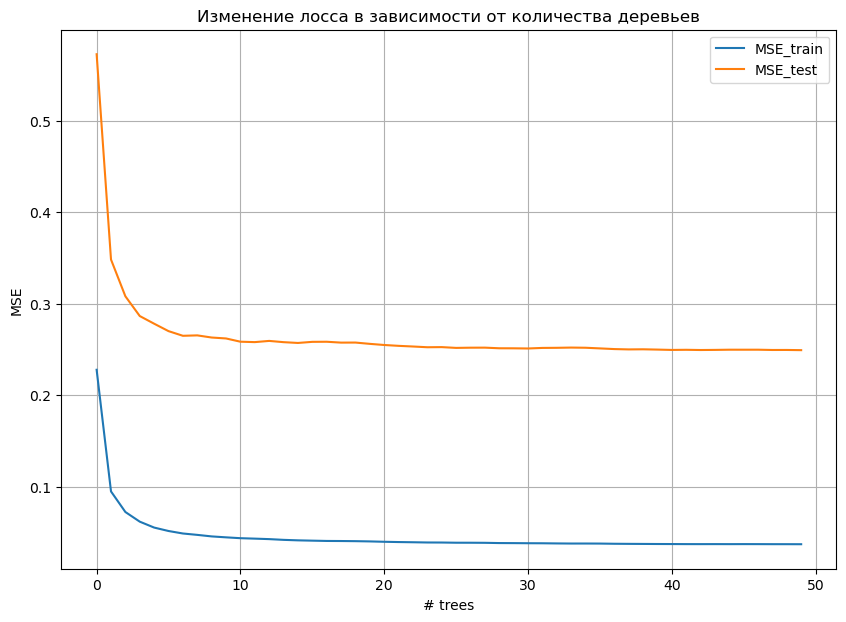

In [13]:
n_trees = 100
train_loss = []
test_loss = []

for i in trange(1, n_trees, 2):
    rf = RandomForestRegressor(n_estimators=i, random_state=123, n_jobs=4)
    rf.fit(X_train, y_train)
    train_loss.append(mean_squared_error(y_train, rf.predict(X_train)))
    test_loss.append(mean_squared_error(y_test, rf.predict(X_test)))

plt.figure(figsize=(10, 7))
plt.title("Изменение лосса в зависимости от количества деревьев")
plt.grid()
plt.plot(train_loss, label="MSE_train")
plt.plot(test_loss, label="MSE_test")
plt.ylabel("MSE")
plt.xlabel("# trees")
plt.legend();

**Вывод:**

После достижения определенного количества деревьев (около 6-7), ошибки обучения и тестирования практически стабилизируются, что указывает на отсутствие переобучения при дальнейшем увеличении количества деревьев. Соответсвенно при увеличении количества деревьев в модели случайного леса, модель не переобучается.

#### Проанализируем поведение случайного леса при изменении максимальной глубины деревьев

  0%|          | 0/25 [00:00<?, ?it/s]

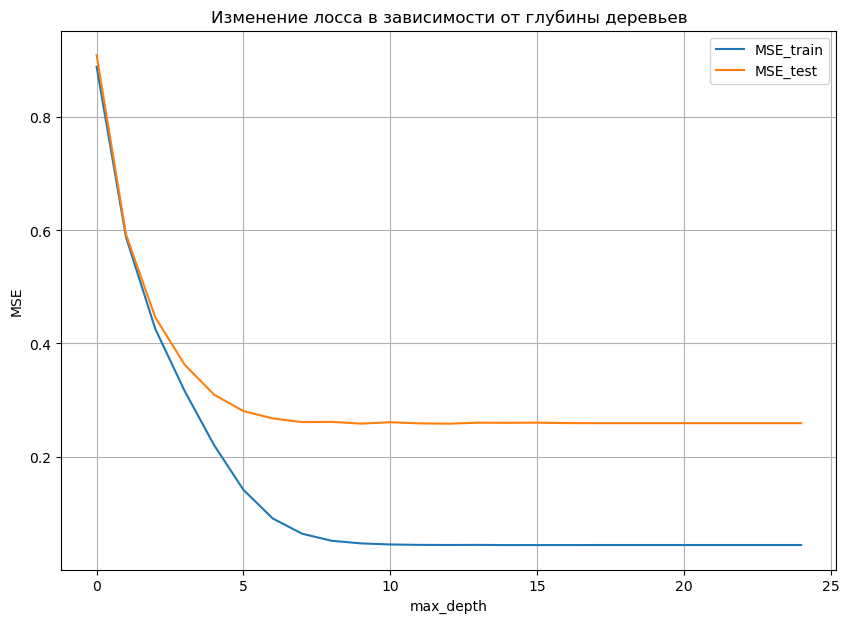

In [14]:
max_depth = 50
train_loss = []
test_loss = []

for i in trange(1, max_depth, 2):
    rf = RandomForestRegressor(n_estimators=20, max_depth=i, random_state=123, n_jobs=4)
    rf.fit(X_train, y_train)
    train_loss.append(mean_squared_error(y_train, rf.predict(X_train)))
    test_loss.append(mean_squared_error(y_test, rf.predict(X_test)))

plt.figure(figsize=(10, 7))
plt.title("Изменение лосса в зависимости от глубины деревьев")
plt.grid()
plt.plot(train_loss, label="MSE_train")
plt.plot(test_loss, label="MSE_test")
plt.ylabel("MSE")
plt.xlabel("max_depth")
plt.legend();

**Вывод:**

При изменении максимальной глубины деревьев, мы наблюдаем похожую картину, как и при изменении количества деревьев, на определенной глубине (около 7-8) средняя квадратическая ошибка стабилизируется. Соответсвенно можно сделать вывод о том, что при изменении максимальной глубины деревьев в модели случайного леса на наших данных, модель не переобучается.

### 2.2. Out-of-bag-ошибка


Средняя ошибка на неиспользованных при обучении экземплярах по всем деревьям случайного леса

In [15]:
rf = RandomForestRegressor(n_estimators=100, random_state=123, oob_score=True, n_jobs=4)
rf.fit(X_train, y_train)
rf.oob_score_

0.800305147049665

**Вывод**

На основе полученной ошибки, можно сказать о том, что модель случайного леса объясняет 80,03% дисперсии целевой переменной (результативного признака), что говорит о достаточной точности и хорошем качестве модели.

### 2.3. Важность признаков

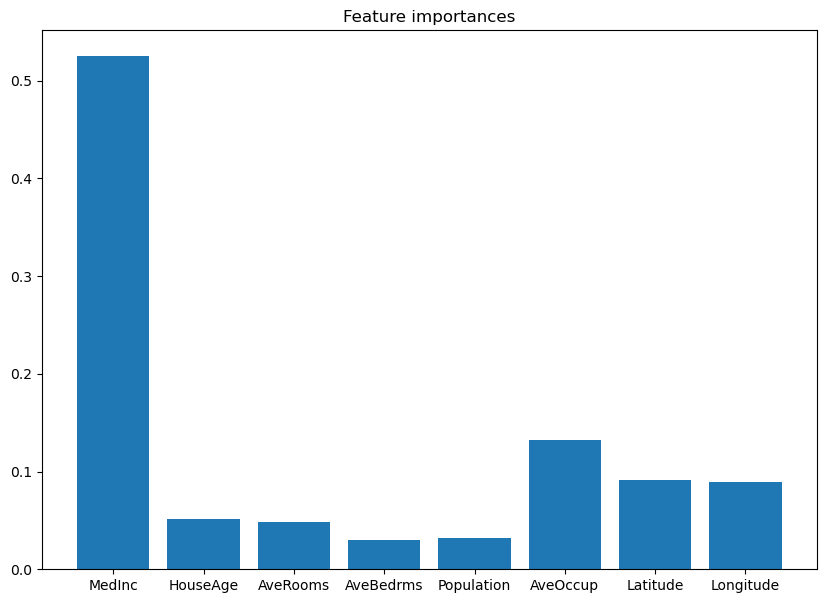

In [16]:
plt.figure(figsize=(10, 7))
plt.title("Feature importances")
plt.bar(california["feature_names"], rf.feature_importances_);

**Вывод**

Рассмотрев диаграмму выше, можно сказать о распределении важности признаков в имеющихся данных.
Признак MedInc - является наиболее важным в выборке. Второй по важности признак - AveOccup, третий - Latitude, четвертый, и очень близкий по значению третьему признаку, - Longitude. 

## 3. Тестирование случайного леса на разных данных (Задание)

### 3.1. Бинарная классификация на примере

Подгрузим данные о грибах 

In [18]:
data = pd.read_csv("mushroom_cleaned.csv")

In [19]:
data

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season,class
0,1372,2,2,10,3.807467,1545,11,1.804273,1
1,1461,2,2,10,3.807467,1557,11,1.804273,1
2,1371,2,2,10,3.612496,1566,11,1.804273,1
3,1261,6,2,10,3.787572,1566,11,1.804273,1
4,1305,6,2,10,3.711971,1464,11,0.943195,1
...,...,...,...,...,...,...,...,...,...
54030,73,5,3,2,0.887740,569,12,0.943195,1
54031,82,2,3,2,1.186164,490,12,0.943195,1
54032,82,5,3,2,0.915593,584,12,0.888450,1
54033,79,2,3,2,1.034963,491,12,0.888450,1


В наших данных целевой переменной будет являться class - съедобный или несъедобный ли гриб, а все остальные признаки факторными. Соответсвенно распределим данные на результативную и факторные признаки:

С помощью функции iloc выберем необходимые столбцы на основе их индексов (позиций)

In [34]:
X = data.iloc[:, :-1]
y = data.iloc[:, -1].values

In [35]:
X

,cap-diameter,cap-shape,gill-attachment,gill-color,stem-height,stem-width,stem-color,season
0,1372,2,2,10,3.807467,1545,11,1.804273
1,1461,2,2,10,3.807467,1557,11,1.804273
2,1371,2,2,10,3.612496,1566,11,1.804273
3,1261,6,2,10,3.787572,1566,11,1.804273
4,1305,6,2,10,3.711971,1464,11,0.943195
...,...,...,...,...,...,...,...,...
54030,73,5,3,2,0.887740,569,12,0.943195
54031,82,2,3,2,1.186164,490,12,0.943195
54032,82,5,3,2,0.915593,584,12,0.888450
54033,79,2,3,2,1.034963,491,12,0.888450


In [36]:
y

array([1, 1, 1, ..., 1, 1, 1], shape=(54035,))

Разделим данные на обучающую и тестовую выборки

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123)

Подгружаем библиотеки

In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

### Обучение логистической регрессии

In [46]:
R = LogisticRegression()
R.fit(X_train, y_train)

y_train_pred = R.predict(X_train)
y_test_pred = R.predict(X_test)

Выведем оценку качества бинарного классификатора roc_auc

In [47]:
roc_auc_test_R = roc_auc_score(y_test, y_test_pred)
print(roc_auc_test_R)

0.627387640954893


### Обучение случайного леса

In [50]:
F = RandomForestClassifier()
F.fit(X_train, y_train)

y_train_pred = F.predict(X_train)
y_test_pred = F.predict(X_test)

Выведем оценку качества бинарного классификатора roc_auc

In [51]:
roc_auc_test_F = roc_auc_score(y_test, y_test_pred)
print(roc_auc_test_F)

0.9903525289945655


### Сравним значения оценок качества AUC ROC на тестовой выборке для регрессии и случайного леса

In [53]:
print("Оценка регрессии:", roc_auc_test_R)
print("Оценка случайного леса:", roc_auc_test_F)

Оценка регрессии: 0.627387640954893
Оценка случайного леса: 0.9903525289945655


Как можно заметить, при сравнении метрик оценки качества для модели логистической регрессии и модели случайного леса на тестовых выборках, Случайный лес показал результат лучше, так как значение метрики очень близко к 1, что говорит о том, что модель хорошо разделяет классы грибов. Модель регресси же имеет значение близкое к 0,5, что говорит, о том, что она занимается почти случайным угадыванием. Соответственно для работы с имеющимися данными о грибах, мы выберем именно модель случайного леса.